# Практическое задание 1: Exploratory Data Analysis

В этом задании вам предстоит предстоит произвести анализ и преобразование твиттов TopG Трампа

In [ ]:
from IPython.display import clear_output
!pip install nltk
!pip install wordcloud
!pip install scikit-learn
clear_output()

In [50]:
import numpy as np
import pandas as pd
from typing import  List
import matplotlib.pyplot as plt
import seaborn as sns
from string import punctuation
from sklearn.feature_extraction.text import CountVectorizer
import nltk
import wordcloud

In [ ]:
df = pd.read_json('trump_truths_dataset.json')
df.head()

,account_name,account_handle,verified_badge,post_date,profile_link,avatar_url,post_url,status_text,video_urls,replies,shares,likes,image_urls
0,Donald J. Trump,realDonaldTrump,True,2024-11-08 10:05:00,https://truthsocial.com/@realDonaldTrump,https://static-assets-1.truthsocial.com/tmtg:p...,https://truthsocial.com/@realDonaldTrump/posts...,"There are fake, untrue, and probably illegal r...",None,429,"1,41k","5,01k",None
1,Donald J. Trump,realDonaldTrump,True,2024-11-07 21:56:00,https://truthsocial.com/@realDonaldTrump,https://static-assets-1.truthsocial.com/tmtg:p...,https://truthsocial.com/@realDonaldTrump/posts...,,None,"4,29k","9,58k","46,2k",[https://static-assets-1.truthsocial.com/tmtg:...
2,Donald J. Trump,realDonaldTrump,True,2024-11-07 21:56:00,https://truthsocial.com/@realDonaldTrump,https://static-assets-1.truthsocial.com/tmtg:p...,https://truthsocial.com/@realDonaldTrump/posts...,,None,"1,11k","6,64k","32,2k",[https://static-assets-1.truthsocial.com/tmtg:...
3,Donald J. Trump,realDonaldTrump,True,2024-11-07 21:56:00,https://truthsocial.com/@realDonaldTrump,https://static-assets-1.truthsocial.com/tmtg:p...,https://truthsocial.com/@realDonaldTrump/posts...,,None,"2,85k","13,3k","63,5k",[https://static-assets-1.truthsocial.com/tmtg:...
4,Donald J. Trump,realDonaldTrump,True,2024-11-07 21:55:00,https://truthsocial.com/@realDonaldTrump,https://static-assets-1.truthsocial.com/tmtg:p...,https://truthsocial.com/@realDonaldTrump/posts...,,None,623,"4,31k","21,8k",[https://static-assets-1.truthsocial.com/tmtg:...


In [ ]:
df.columns

Index(['account_name', 'account_handle', 'verified_badge', 'post_date',
       'profile_link', 'avatar_url', 'post_url', 'status_text', 'video_urls',
       'replies', 'shares', 'likes', 'image_urls'],
      dtype='object')

Для каждого поста указано:

* account_name — имя аккаунта пользователя (например, "Donald J. Trump")
* account_handle — уникальный логин пользователя (например, "@realDonaldTrump")
* verified_badge — наличие верификации аккаунта
* post_date — дата и время публикации поста
* profile_link — ссылка на профиль пользователя в социальной сети
* avatar_url — ссылка на аватар пользователя
* post_url — ссылка на сам пост
* status_text — текст публикации (основное содержание, текстовый пост)
* video_urls - ссылка на видео
* replies — количество ответов на пост
* shares — количество репостов или делений постом
* likes — количество лайков поста
* image_urls - ссылки на картинки/видео


In [ ]:
len(df)

5159

## Задание 1 Подготовка (1 балл)

Иногда для знакомства с датасетом бывает полезно взглянуть на облако слов. Для этого можно использовать библиотеку `wordcloud`. Выведите облако слов для текста пост

In [5]:
from wordcloud import WordCloud

def create_cloud_graph(corpus):
    wordcloud = WordCloud(
        width=1600, height=800, max_words=200, background_color='white', collocations=False
    ).generate(' '.join(corpus))
    plt.figure(figsize=(20,10))
    plt.imshow(wordcloud)
    plt.axis("off")
    plt.show()

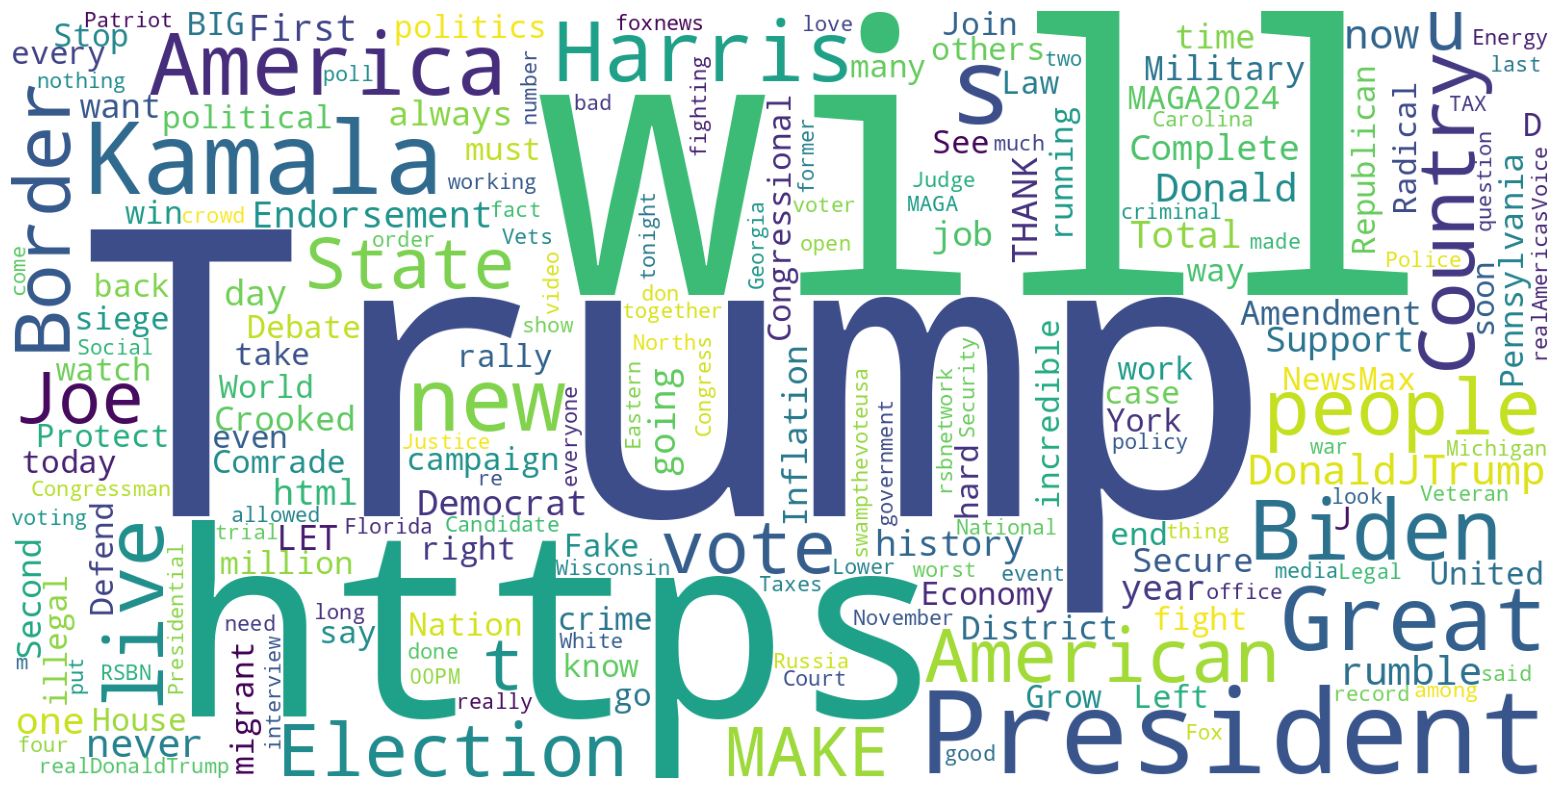

In [6]:
create_cloud_graph(df['status_text'])

Приведите столбец `post_date` к типу `datetime`, чтобы работать с датами.

In [7]:
df['post_date'] = pd.to_datetime(df['post_date'])
df['post_date'].head()

0   2024-11-08 10:05:00
1   2024-11-07 21:56:00
2   2024-11-07 21:56:00
3   2024-11-07 21:56:00
4   2024-11-07 21:55:00
Name: post_date, dtype: datetime64[ns]

Преобразуйте метрики вовлечённости (`likes`, `replies`, `shares`) в численный формат:
   - Обработайте значения вида "5,01k", "1,41k" в 5010 и 1410 соответственно.
   - Пропущенные значения замените на 0.
   - Результатом должны быть числа, отражающие реальное количество лайков, ответов и репостов.

In [41]:
def convert_interaction(value):
    if pd.isna(value):
        return 0

    value = str(value).strip().lower().replace(',', '.')
    if value.endswith('k'):
        return int(round(float(value[:-1]) * 1000))
    return int(float(value))

df['likes_count'] = df['likes'].apply(convert_interaction)
df['replies_count'] = df['replies'].apply(convert_interaction)
df['shares_count'] = df['shares'].apply(convert_interaction)

df[['likes', 'replies', 'shares', 'likes_count', 'replies_count', 'shares_count']].head()

,likes,replies,shares,likes_count,replies_count,shares_count
0,"5,01k",429,"1,41k",5010,429,1410
1,"46,2k","4,29k","9,58k",46200,4290,9580
2,"32,2k","1,11k","6,64k",32200,1110,6640
3,"63,5k","2,85k","13,3k",63500,2850,13300
4,"21,8k",623,"4,31k",21800,623,4310


Создайте два бинарных признака:
   - `has_video` — 1, если пост содержит видео, иначе 0
   - `has_image` — 1, если пост содержит изображение, иначе 0

In [9]:
df['has_video'] = df['video_urls'].notna().astype(int)
df['has_image'] = df['image_urls'].notna().astype(int)

df[['has_video', 'has_image']].head()

,has_video,has_image
0,0,0
1,0,1
2,0,1
3,0,1
4,0,1


Выведете на экран информацию о пропусках в данных. Если пропуски присутствуют заполните их строкой 'Unknown'.

In [10]:
print('Пропуски до заполнения:')
print(df.isna().sum())

df = df.fillna('Unknown')

print('\nПропусков после заполнения:', df.isna().sum().sum())

Пропуски до заполнения:
account_name         0
account_handle       0
verified_badge       0
post_date            0
profile_link         1
avatar_url           0
post_url           761
status_text          0
video_urls        4165
replies              0
shares               0
likes                0
image_urls        3867
likes_count          0
replies_count        0
shares_count         0
has_video            0
has_image            0
dtype: int64

Пропусков после заполнения: 0


## Задание 2 - Построение графиков (2 балла)

Чтобы посмотреть в каких диапозонах лежат наши данные, давайте посмотрим на них внимательнее

Постройте график распределения по лайкам, репостам, комментариям в виде столбчатой диаграммы. Визуализируйте распределение метрик вовлечённости с помощью strip-плота, чтобы увидеть разброс значений.


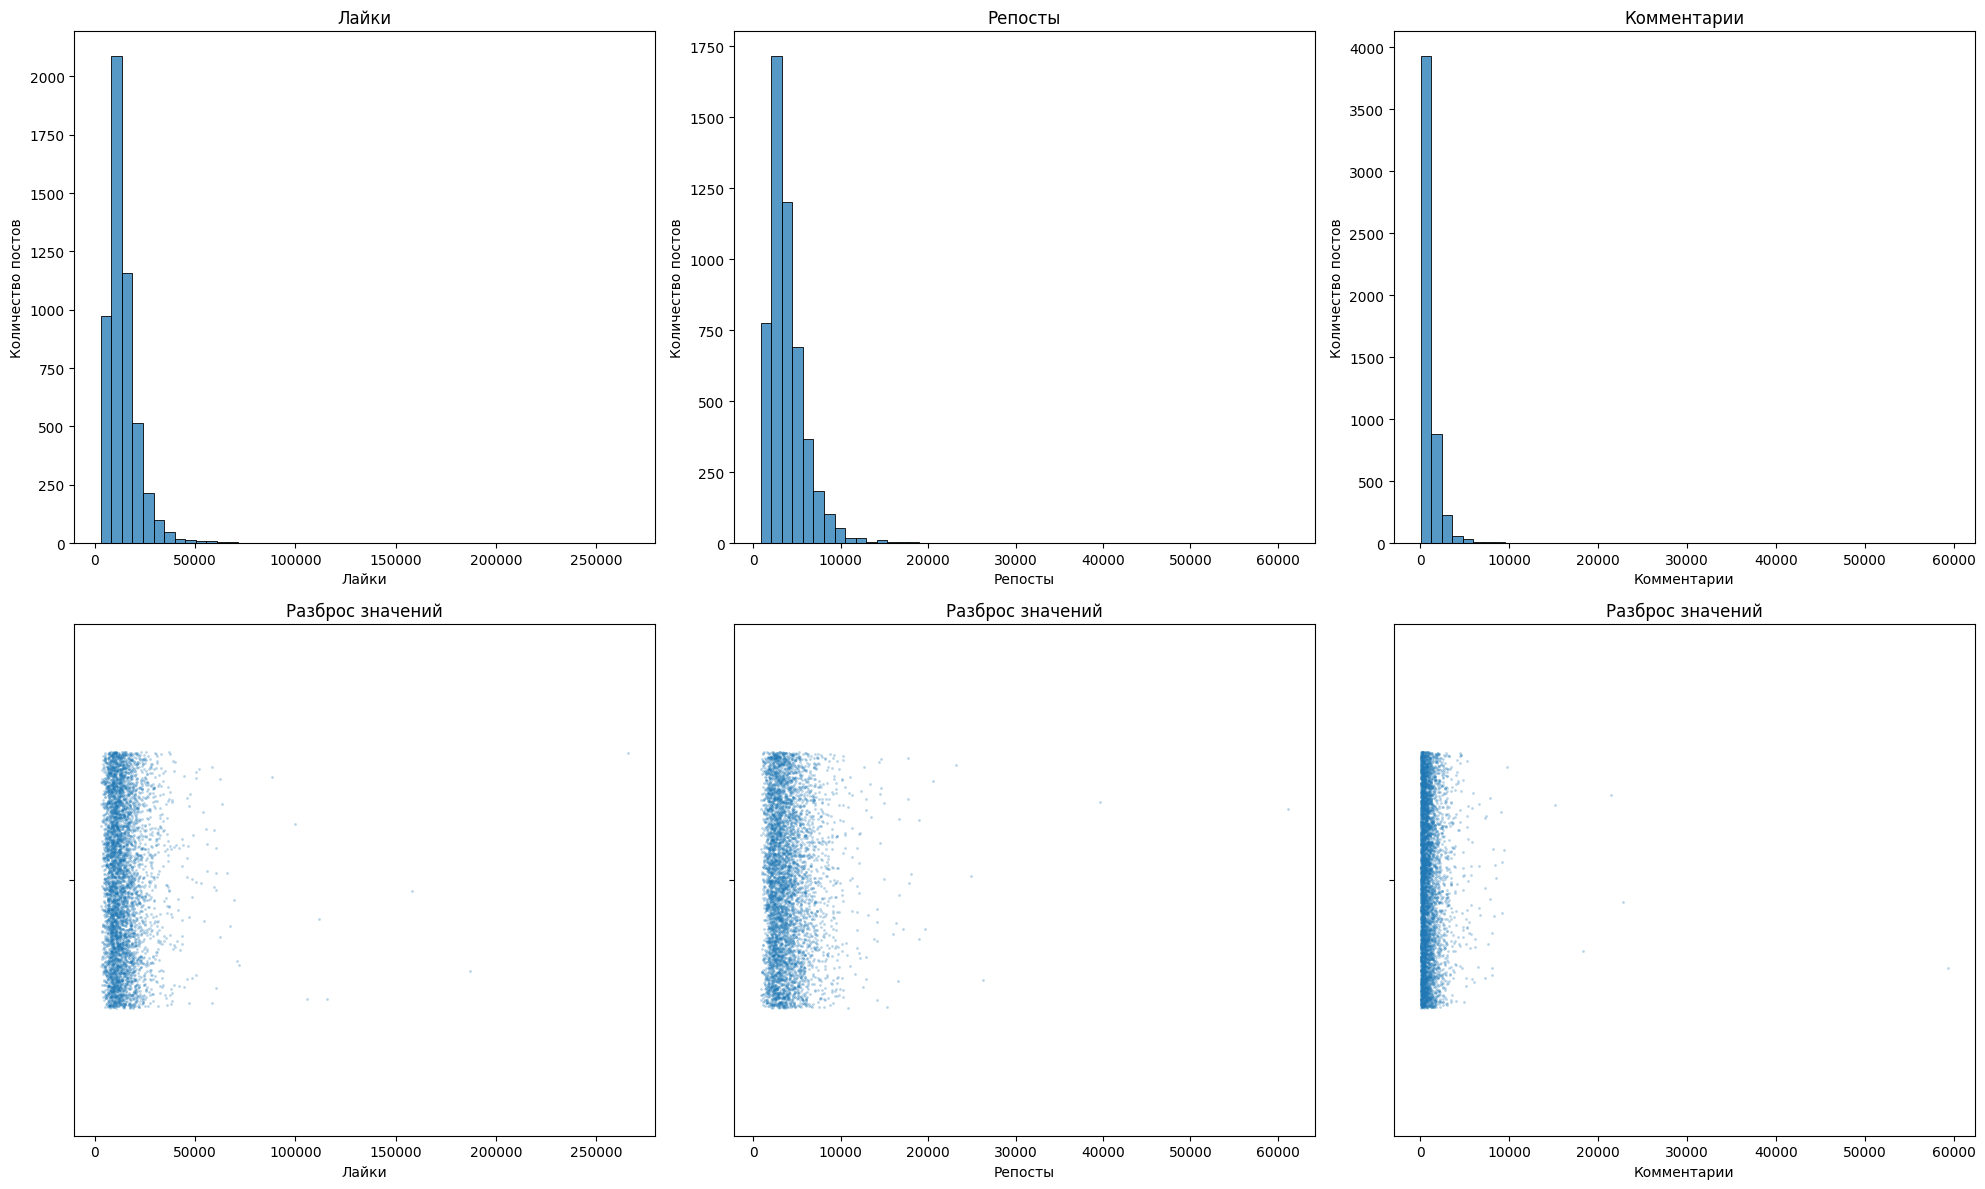

In [36]:
metrics = ['likes_count', 'shares_count', 'replies_count']
labels = ['Лайки', 'Репосты', 'Комментарии']

fig, axes = plt.subplots(2, 3, figsize=(20, 12))

for i, column in enumerate(metrics):
    sns.histplot(data=df, x=column, bins=50, ax=axes[0, i])
    axes[0, i].set_title(labels[i])
    axes[0, i].set_xlabel(labels[i])
    axes[0, i].set_ylabel('Количество постов')

    sns.stripplot(x=df[column], jitter=0.25, size=2, alpha=0.3, ax=axes[1, i])
    axes[1, i].set_title('Разброс значений')
    axes[1, i].set_xlabel(labels[i])

plt.tight_layout()
plt.show()

Постройте круговую диаграмму, отражающую распределение постов по типу контента: с видео, с изображениями и только текст.

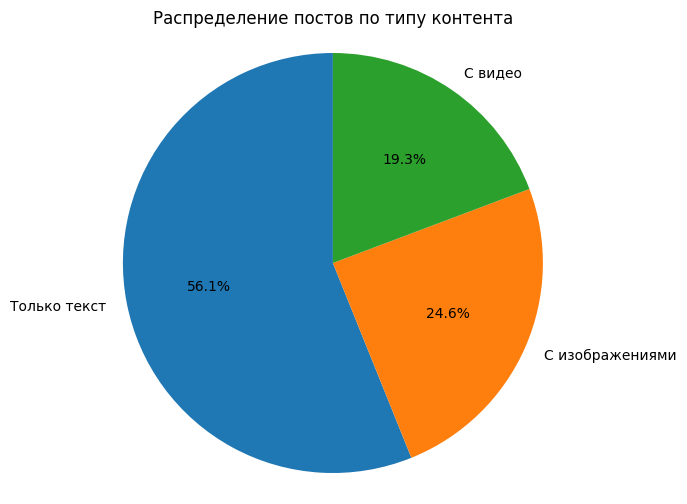

In [38]:
df['content_type'] = 'Только текст'
df.loc[df['has_image'] == 1, 'content_type'] = 'С изображениями'
df.loc[df['has_video'] == 1, 'content_type'] = 'С видео'
# Я отнес посты с несколькими категориями к последней категории, к примеру было изображение + текст - относим к изображению

content_counts = df['content_type'].value_counts()
plt.figure(figsize=(8, 6))
plt.pie(content_counts, labels=content_counts.index, autopct='%1.1f%%', startangle=90)
plt.title('Распределение постов по типу контента')
plt.axis('equal')
plt.show()

Соберите статистику по данным:
   - общее количество постов
   - среднее по лайкам, репостам и комментариям

   
Придумайте и выведите ещё 3 статистики, которые вы считаете важными для понимания данных

In [9]:
print('Общее количество постов:', len(df))

statistics = df[metrics].agg(['mean', 'median', 'max', 'std'])
statistics.index = ['Среднее', 'Медиана', 'Максимум', 'Стандартное отклонение']
statistics.columns = labels
statistics.round(1)

Общее количество постов: 5159


,Лайки,Репосты,Комментарии
Среднее,14084.7,3855.1,941.7
Медиана,12100.0,3320.0,614.0
Максимум,266000.0,61200.0,59400.0
Стандартное отклонение,9303.1,2359.1,1380.2


Сделайте выводы:
   - Какой тип контента вызывает больше реакций?
   - Как выглядит распределение проявлений активности?
   - Есть ли выбросы в данных?

In [47]:
mean_reactions = df.groupby('content_type')[metrics].mean()
mean_reactions.columns = labels
mean_reactions['Всего реакций'] = mean_reactions.sum(axis=1)

q1 = df[metrics].quantile(0.25)
q3 = df[metrics].quantile(0.75)
iqr = q3 - q1
outliers = ((df[metrics] < q1 - 1.5 * iqr) | (df[metrics] > q3 + 1.5 * iqr)).sum()
outliers.index = labels
print('Количество выбросов по правилу межквартильного размаха:')
print(outliers)

mean_reactions.round(1)

Количество выбросов по правилу межквартильного размаха:
Лайки          238
Репосты        221
Комментарии    328
dtype: int64


,Лайки,Репосты,Комментарии,Всего реакций
content_type,,,,
С видео,14546.3,4225.9,952.8,19725.0
С изображениями,12946.2,3516.9,738.7,17201.8
Только текст,14426.2,3876.3,1027.0,19329.5


**Ответ:**

- Больше всего реакций в среднем получают посты с видео, около 19 725 на пост. У текстовых постов около 19 329, у постов с изображениями около 17 202.
- Из графика, который был построин выше видно, что распределения скошены вправо. Большинство постов имеет умеренную активность, только несколько постов получает очень много реакций. Также это подтверждается тем, что средние выше медиан.
- По правилу 1,5 межквартильного размаха выбросы есть, 238 по лайкам, 221 по репостам и 328 по комментариям. Эти группы могут пересекаться, поэтому складывать их количества нельзя.

## Задание 3 Токенизация (5 баллов)

- **Токен** — это отдельная единица текста, например, слово, слог или символ
- **Токенизация** — процесс разбиения текста на токены.  
- **Токенизатор** — инструмент, который выполняет это разбиение.  

Постройте частотный словарь токенов на основе столбца `status_text` и посчитайте количество встреч каждого токена с использованием самой простой токенизации - деления текстов по пробельным символам и приведение токенов в нижний регистр

In [ ]:
vectorizer = CountVectorizer(tokenizer=str.split, token_pattern=None)

word_matrix = vectorizer.fit_transform(df['status_text'])
word_counts = pd.Series(
    np.asarray(word_matrix.sum(axis=0)).ravel(),
    index=vectorizer.get_feature_names_out()
).sort_values(ascending=False)

Какой размер словаря получился?

In [51]:
print('Размер словаря:', len(word_counts))

Размер словаря: 17306


Выведите 10 самых популярных токенов с количеством встреч каждого из них. Объясните, почему именно эти токены в топе

In [9]:
word_counts.head(10)

the     5992
and     4428
to      3361
of      2796
a       2541
in      2262
is      2143
our     1644
will    1551
for     1439
dtype: int64

**Ответ:**<br> 
В словаре 17 306 уникальных токенов. В топе находятся частые английские артикли и служебные слова, такие как the, and, to, of, a. Они нужны для построения предложений и встречаются в текстах на разные темы, поэтому мало говорят о содержании постов. Также важно учитывать, что наше разбиение не отделяет пунктуацию, например, *trump* и *trump,* считаются разными токенами.

Стоп-слова — это распространённые слова, которые не несут большой смысловой нагрузки в контексте анализа текста. Обычно это предлоги, союзы, артикли, вспомогательные глаголы и т.п., например:

- ['the', 'is', 'and', 'in', 'of', 'to', 'a', 'an', 'on', 'with']

Удалите стоп-слова из словаря, используя stopwords из библиотеки nltk и выведите новый топ-10 токенов (и количество встреч) по популярности. Что можно сказать  о нем?

In [52]:
import nltk
from nltk.corpus import stopwords

stop_words = set(stopwords.words('english'))
word_counts_no_stop = word_counts[~word_counts.index.isin(stop_words)]
word_counts_no_stop.head(10)

president    707
great        694
trump        669
kamala       641
-            443
america      442
people       411
make         367
joe          356
never        334
dtype: int64

**Ответ:**<br>
После удаления стоп-слов в топе появились как раз те слова, что нам нужны: president, great, trump, kamala, america ... Они отражают политическую тематику постов. Но очистка все ещё неполная, к примеру в топе остался дефис и слова со знаками препинания по прежнему считаются отдельно.

Также выведите 20 самых непопулярных слов (если самых непопулярных слов больше выведите любые 20 из них) Почему эти токены непопулярны, требуется ли как-то дополнительно работать с ними?

In [11]:
word_counts_no_stop.sort_values().head(20)

harvard                   1
killer                    1
killed.                   1
kill.                     1
kill,                     1
harris...she              1
harris.#bringbacktrump    1
harris."                  1
hashed                    1
has.                      1
kilmeade.                 1
harshly                   1
harshbarger.              1
kirk!                     1
kinzinger,                1
king,                     1
hatchet                   1
has”                      1
hastily                   1
have,                     1
dtype: int64

**Ответ:**<br> 
У всех выведенных токенов частота равна 1. Среди них есть редкие имена, обычные слова, слова с пунктуацией (killed. / kill,) и склеенные фрагменты (harris.#bringbacktrump). Удалять все редкие токены автоматически не стоит, так как в них может быть полезная информация.

Теперь воспользуемся токенайзером получше - TweetTokenizer из библиотеки nltk. Примените его и посмотрите на топ-10 популярных слов. Чем он отличается от топа, который получался раньше? Почему?

In [56]:
from nltk.tokenize import TweetTokenizer
from collections import Counter

tweet_tokenizer = TweetTokenizer()
tweet_counts = Counter()
for text in df['status_text']:
    tweet_counts.update(tweet_tokenizer.tokenize(text.lower()))

pd.Series(tweet_counts).sort_values(ascending=False).head(10)

,      10290
the     6121
.       5817
and     4596
!       3872
to      3402
of      2807
a       2642
in      2312
is      2184
dtype: int64

**Ответ:**<br> 
В топе появились отдельные препинания, к примеру запята, точка и восклицательный знак. TweetTokenizer отделяет их от слов, поэтому частоты самих слов тоже изменились, например, the теперь встречается 6121 раз вместо 5992. Поэтому такой токенайзер лучше обрабатывает тексты соцсетей, сохраняя хештеги, упоминания и ссылки отдельными токенами.

Удалите из словаря стоп-слова и пунктуацию посмотрите на новый топ-10 слов с количеством встреч, есть ли теперь в нем что-то не похожее на слова?

In [58]:
from string import punctuation

clean_counts = Counter({
    token: count for token, count in tweet_counts.items()
    if token not in stop_words and token.strip(punctuation)
})

pd.Series(clean_counts).sort_values(ascending=False).head(10)

’            1836
trump        1112
“             985
”             969
president     887
—             850
kamala        823
great         713
america       618
…             522
dtype: int64

**Ответ:**<br> 
После удаления стоп-слов и пунктуации в топе стали появляться содержательные слова (trump, president, kamala), но также видны остались разные кавычки, длинное тире и троеточие. Они не входят в string.punctuation, поэтому мы их не удаляем.

Удалите из словаря токены из одного символа, с позицией в таблице Unicode 128 и более (`ord(x) >= 128`)

Выведите топ-10 самых популярных и топ-20 непопулярных слов. Чем полученные топы отличаются от итоговых топов, полученных при использовании токенизации по пробелам? Что теперь лучше, а что хуже?

In [59]:
clean_counts = Counter({
    token: count for token, count in clean_counts.items()
    if not (len(token) == 1 and ord(token) >= 128)
})

print('Топ-10 популярных токенов:')
print(pd.Series(clean_counts).sort_values(ascending=False).head(10))

print('\nТоп-20 непопулярных токенов:')
print(pd.Series(clean_counts).sort_values().head(20))

Топ-10 популярных токенов:
trump        1112
president     887
kamala        823
great         713
america       618
country       509
harris        503
biden         493
people        489
border        430
dtype: int64

Топ-20 непопулярных токенов:
https://www.bloomberg.com/news/articles/2024-02-01/ex-soros-cio-bessent-bets-on-trump-rally-ahead-of-us-election    1
bets                                                                                                                1
https://www.rsbnetwork.com/news/its-time-to-flip-new-york-red-president-trump-rallies-in-the-bronx/                 1
https://www.rsbnetwork.com/news/yankee-stadium-gets-a-trump-surprise-just-before-his-south-bronx-visit/             1
https://www.rsbnetwork.com/news/how-to-watch-president-trump-in-the-south-bronx/                                    1
ceiling                                                                                                             1
americasvoice.news/justthenews/ohio-expand

**Ответ:**<br> 
После удаления одиночных символов с кодом Unicode от 128 топ состоит только из содержательных слов. По сравнению с разбиением по пробелам пунктуация лучше отделяется от слов и варианты одного слова чаще объединяются. Но в редких токенах остаются ссылки, даты, имена и склеенные слова, например, nywhile. Кроме того, удаление всех одиночных символов после 128 позиции в Unicode грубое, так как вместе с шумом можно потерять полезные символы.

Выведите топ-10 популярных хештегов с количеством встреч. Что можно сказать о них?

In [15]:
hashtag_counts = Counter({
    token: count for token, count in clean_counts.items()
    if token.startswith('#') and len(token) > 1
})
pd.Series(hashtag_counts).sort_values(ascending=False).head(10)

#trump2024        24
#toobigtorig      20
#maga             18
#swampthevote     10
#phpnews           8
#truth             7
#americafirst      5
#maga4thefelon     5
#notaxontips       5
#trumpforce47      5
dtype: int64

**Ответ:**<br>
Топ 3 по хэштегам: #trump2024 (24), #toobigtorig (20), #maga (18). Они в основном связаны с предвыборной кампанией и политическими лозунгами.

То же самое удалите ссылки https, https на сайты и посмотрите, как изменился размер словаря. Будет ли информация о ссылке на конкретную страницу полезна в текстах постов?

In [60]:
counts_no_links = Counter({
    token: count for token, count in clean_counts.items()
    if not token.startswith(('http://', 'https://'))
})

print('Размер словаря до удаления ссылок:', len(clean_counts))
print('Размер словаря после удаления ссылок:', len(counts_no_links))
print('Удалено ссылок:', len(clean_counts) - len(counts_no_links))

Размер словаря до удаления ссылок: 10068
Размер словаря после удаления ссылок: 9200
Удалено ссылок: 868


**Ответ:**<br>
После удаления ссылок с http:// и https:// словарь сократился с 10 068 до 9200 токенов. Адреса отдельных страниц часто уникальны и увеличивают словарь, не раскрывая содержание всей страницы, поэтому для анализа текста их удаление разумно. Однако адреса без протокола, например americasvoice.news/, этот фильтр не удаляет.

Используем опыт предыдущих экспериментов и напишем собственный токенайзер, улучшив TweetTokenizer. Функция tokenize должна:



*   Привести текст в нижний регистр
*   Применить TweetTokenizer для изначального выделения токенов
*   Удалить стоп-слова, пунктуацию, ссылки, токены из одного символа, с позицией в таблице Unicode 128 и более



In [63]:
def tokenize(text):
    tokens = tweet_tokenizer.tokenize(text.lower())
    tokens = [
        token for token in tokens
        if token not in stop_words
        and token.strip(punctuation)
        and not token.startswith(('http://', 'https://'))
        and not (len(token) == 1 and ord(token) >= 128)
    ]
    return tokens

In [67]:
tokenize('This is пример text!!!! @Sample_text I, https://t.co/sample  #magamagamaga228_67_52')

['пример', 'text', '@sample_text', '#magamagamaga228_67_52']

## Задание 4 Стемминг и Лемматизация (2 балла)

- Стемминг — это процесс приведения слов к их основе, то есть корню, который не обязательно является реальным словом в языке. Например, слово "running" превращается в "runn" или "run" в зависимости от алгоритма.


- Лемматизация — это более сложный процесс, при котором слово приводится к своей лемме (словарной форме), с учётом его грамматической роли и части речи. Например, "running" → "run", "better" → "good.

Модифицируйте написанный токенайзер, добавив в него стемминг и лемматизацию из библиотеки nltk - PorterStemmer, WordNetLemmatizer


Как изменился размер словаря в случае лемантизации и стемминга?

In [70]:
from nltk.stem import PorterStemmer

stemmer = PorterStemmer()

def custom_stem_tokenizer(text):
    tokens = tokenize(text)
    return [stemmer.stem(token) for token in tokens]

In [72]:
custom_stem_tokenizer('This is пример text!!!! @Sample_text I, https://t.co/sample  #magamagamaga228_67_52 adding more words to check stemming')

['пример',
 'text',
 '@sample_text',
 '#magamagamaga228_67_52',
 'ad',
 'word',
 'check',
 'stem']

In [74]:
base_vectorizer = CountVectorizer(tokenizer=tokenize, token_pattern=None, lowercase=False)
base_vectorizer.fit(df['status_text'])
base_vocab_size = len(base_vectorizer.vocabulary_)

cv = CountVectorizer(tokenizer=custom_stem_tokenizer, token_pattern=None, lowercase=False)
cv.fit(df['status_text'])
stem_vocab_size = len(cv.vocabulary_)

print('Размер словаря до стемминга:', base_vocab_size)
print('Размер словаря после стемминга:', stem_vocab_size)
print('Изменение:', base_vocab_size - stem_vocab_size)

Размер словаря до стемминга: 9200
Размер словаря после стемминга: 6856
Изменение: 2344


**Ответ:**<br>
После стемминга размер словаря сократился с 9200 до 6856 токенов. Это произошло как раз из за объединения разных форм слов, отсекая окончания, например, `adding` превратился в `ad`. 

In [75]:
from nltk.stem import WordNetLemmatizer

lemmatizer = WordNetLemmatizer()

def custom_lem_tokenizer(text):
    tokens = tokenize(text)
    return [lemmatizer.lemmatize(token) for token in tokens]

In [80]:
custom_stem_tokenizer('This is пример text!!!! @Sample_text I, https://t.co/sample  #magamagamaga228_67_52 adding more words to check lemming')

['пример',
 'text',
 '@sample_text',
 '#magamagamaga228_67_52',
 'ad',
 'word',
 'check',
 'lem']

In [82]:
cv = CountVectorizer(tokenizer=custom_lem_tokenizer, token_pattern=None, lowercase=False)
cv.fit(df['status_text'])
lem_vocab_size = len(cv.vocabulary_)

print('Размер словаря до лемматизации:', base_vocab_size)
print('Размер словаря после лемматизации:', lem_vocab_size)
print('Изменение:', base_vocab_size - lem_vocab_size)

Размер словаря до лемматизации: 9200
Размер словаря после лемматизации: 8428
Изменение: 772


**Ответ:**<br>
После лемматизации размер словаря сократился с 9200 до 8428 токенов. Сокращение меньше, чем при стемминге. Лемматизация обычно сохраняет словарные формы, например, `words` превращается в `word`, а `sample` остаётся `sample`.

Теперь разделите данные на обучающие и тестовые в соотношении 7 : 3 и random_state=0

In [83]:
from sklearn.model_selection import train_test_split

train, test = train_test_split(df, test_size=0.3, random_state=0)
print('Количество постов в train:', len(train))
print('Количество постов в test:', len(test))

Количество постов в train: 3611
Количество постов в test: 1548


Итак, у нас получился очищенный корпус слов, на котором уже можно запускать и обучать модели.

Поздравляю! Вы большие молодцы и прошли первый этап практики) Приступайте к следующему заданию!